Testing out the concept of slope steepening by varying self-weight

In [70]:
import scipy.integrate as int
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

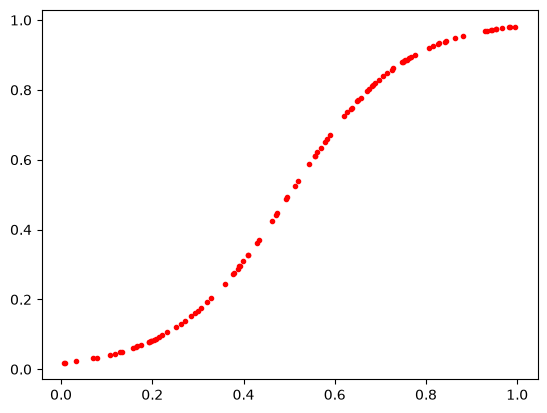

In [3]:
# Using a logistic curve as a baseline sigmoid function
# Maximum slope is kL/4, and want L=1 to keep [0,1] range

k = 8
L = 1
x0 = 0.5
def sigma(x):
    return L/(1+np.exp(-k*(x-x0)))

xrandom = np.random.rand(100)
plt.plot(xrandom,sigma(xrandom),'r.')

In [64]:
#ODE setup
def biasfun(t):
    return 0.5*(-np.cos(t*np.pi)+1)/2
tau = 1/1000
self_weight = 0.2
def rhs(t,x):
    nextx = -x + biasfun(t) + self_weight*sigma(x)
    return nextx*(1/tau)

result = int.solve_ivp(rhs,[0,4],[0],atol=1e-6,rtol=1e-6)

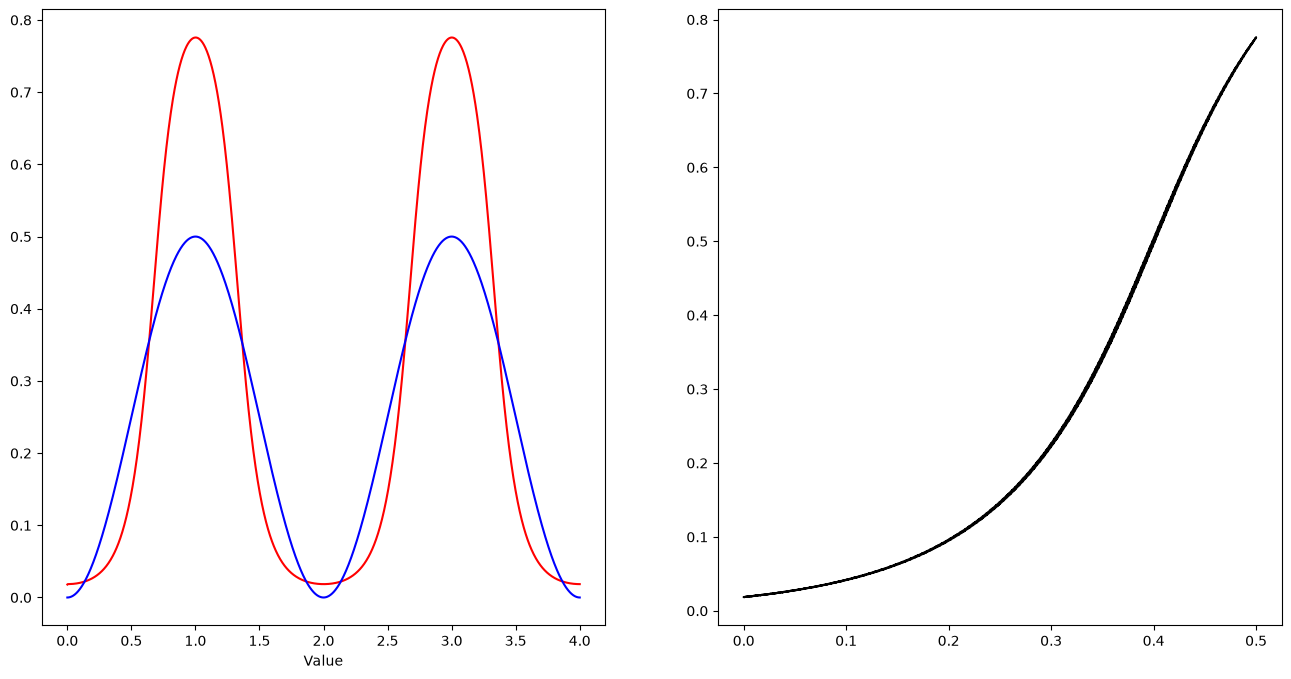

In [65]:
plt.subplots(1,2,figsize=[16,8])
yout = sigma(result.y[0].T)
tout = result.t
plt.subplot(1,2,1)
plt.plot(tout,yout,'r-')
plt.plot(tout,biasfun(tout),'b-')
plt.xlabel('Time')
plt.xlabel('Value')
plt.subplot(1,2,2)
plt.plot(biasfun(tout),yout,'k-.')

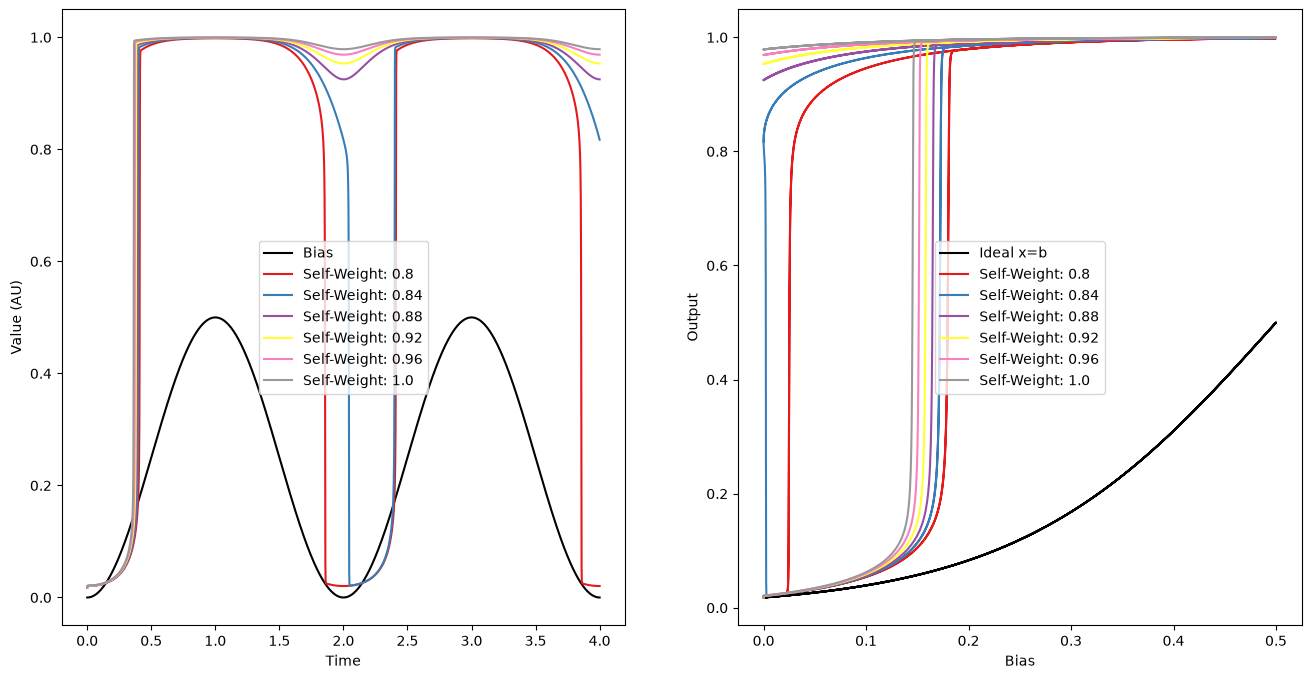

In [88]:
#Sweep the strength of self-weighting
alpha_array = np.arange(0.8,1.0+0.001,0.04)

plt.subplots(1,2,figsize=[16,8])
cmap = mpl.colormaps['Set1']
colors = cmap(np.linspace(0,1,len(alpha_array)))

for i in range(len(alpha_array)):
    alpha = alpha_array[i]
    tau = 1/1000
    def rhsi(t,x):
        nextx = -x + biasfun(t) + alpha*sigma(x)
        return nextx*(1/tau)
    resulti = int.solve_ivp(rhsi,[0,4],[0],atol=1e-8,rtol=1e-8)
    youti = sigma(resulti.y[0].T)
    touti = resulti.t
    plt.subplot(1,2,1)
    if i == 0:
        plt.plot(touti,biasfun(touti),'k-')
    plt.plot(touti,youti,'-',color=colors[i])
    plt.subplot(1,2,2)
    if i == 0:
        plt.plot(biasfun(touti),sigma(biasfun(touti)),'k-')
    plt.plot(biasfun(touti),youti,'-',color=colors[i])

plt.subplot(1,2,1)
plt.xlabel('Time')
plt.ylabel('Value (AU)')
plt.legend(['Bias']+[f'Self-Weight: {np.round(a,2)}' for a in alpha_array])

plt.subplot(1,2,2)
plt.xlabel('Bias')
plt.ylabel('Output')
plt.legend(['Ideal x=b']+[f'Self-Weight: {np.round(a,2)}' for a in alpha_array])